# 04 · Random Forest (from scratch)

Implementation: `src/random_forest.py` (built on our own decision tree). We investigate:
1. **number of trees**
2. **number of features considered at each split** (`max_features`)
3. **maximum tree depth**
4. **minimum samples per leaf**

and compare the forest against the single Decision Tree from notebook 03.

`N_JOBS = -1` builds trees in parallel on all CPU cores (results are identical to 1 core).

In [1]:
import sys
import json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.common import *
from src.plotting import *
from src.random_forest import RandomForestClassifier
set_seed()

N_JOBS = -1
N_TREES = 400             # size of the main forests
SWEEP_TREES = 60          # trees per forest in the parameter sweeps (keeps run time reasonable)
splits = {t: get_split(t) for t in ("image", "sentiment")}

## 1 · Number of trees
One forest of 400 trees per task. Because the trees are independent, "the forest made of the first
*n* trees" is exactly a forest with `n_estimators = n`, so one forest gives the whole curve.

In [2]:
rows, big = [], {}
for task, (Xtr, ytr, Xva, yva) in splits.items():
    with Timer() as t:
        rf = RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", random_state=SEED,
                                    n_jobs=N_JOBS).fit(Xtr, ytr, N_CLASSES[task])
    big[task] = (rf, t.seconds)
    print(f"{task}: {N_TREES} trees in {t.seconds:.0f}s, OOB accuracy {rf.oob_score_:.4f}")
    for n, proba in enumerate(rf.staged_predict_proba(Xva), start=1):
        rows.append(dict(task=task, n_trees=n, val_acc=accuracy(yva, proba.argmax(1))))
ntree_results = pd.DataFrame(rows)
save_table(ntree_results, "rf_n_trees")
print(ntree_results[ntree_results.n_trees.isin([1, 5, 10, 25, 50, 100, 200, 300, 400])]
      .pivot(index="n_trees", columns="task", values="val_acc").round(4))

image: 400 trees in 552s, OOB accuracy 0.3143


sentiment: 400 trees in 71s, OOB accuracy 0.6094


task      image  sentiment
n_trees                   
1        0.0798     0.4038
5        0.1035     0.4792
10       0.1328     0.5004
25       0.1932     0.5529
50       0.2490     0.5812
100      0.2932     0.5946
200      0.3355     0.6029
300      0.3530     0.6038
400      0.3662     0.6029


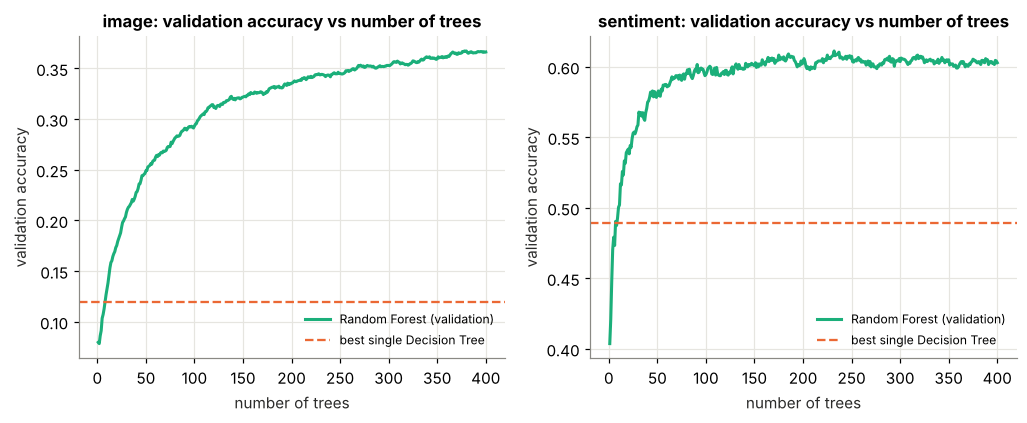

In [3]:
dt_info = {t: json.load(open(PRED_DIR / f"{t}_dt.json")) for t in splits}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    r = ntree_results[ntree_results.task == task]
    ax.plot(r.n_trees, r.val_acc, color=PALETTE[2], label="Random Forest (validation)")
    ax.axhline(dt_info[task]["val_acc"], color=PALETTE[1], linestyle="--", linewidth=1.5,
               label="best single Decision Tree")
    ax.set_xlabel("number of trees"); ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task}: validation accuracy vs number of trees")
    ax.legend(fontsize=8)
savefig(fig, "04_rf_n_trees"); plt.show()

* **Sentiment:** one tree scores ≈ 40%. The forest climbs quickly and levels off at ≈ 60% after ~100–150 trees.
* **Images:** one tree scores 8%, 400 trees reach 36.6%, and accuracy is *still* rising (≈ +1.3% per
  extra 100 trees). With 50 classes and weak individual features, each tree is a very noisy voter, so
  many more votes are needed before the average settles.
* **OOB accuracy** (31.4% image / 60.9% sentiment at 400 trees) scores each training row using only the
  ~37% of trees that did not see it, i.e. a forest of ~150 trees. That is why, on images, it sits
  below the validation accuracy of the full 400-tree forest.

## 2 · Features tried per split (`max_features`)
Fewer features per split = more different (de-correlated) trees, but each tree is individually weaker.

In [4]:
def sweep(param, values, base):
    rows = []
    for task, (Xtr, ytr, Xva, yva) in splits.items():
        for v in values:
            cfg = dict(base, **{param: v})
            with Timer() as t:
                rf = RandomForestClassifier(n_estimators=SWEEP_TREES, random_state=SEED, n_jobs=N_JOBS,
                                            **cfg).fit(Xtr, ytr, N_CLASSES[task])
            rows.append(dict(task=task, param=param, value=str(v),
                             train_acc=accuracy(ytr, rf.predict(Xtr)), val_acc=accuracy(yva, rf.predict(Xva)),
                             oob_acc=rf.oob_score_, fit_s=round(t.seconds, 1)))
            print(f"{task:9s} {param}={v}: val {rows[-1]['val_acc']:.4f} ({t.seconds:.0f}s)")
    return pd.DataFrame(rows)

base = dict(max_features="sqrt", max_depth=None, min_samples_leaf=1)
mf_results = sweep("max_features", ["log2", "sqrt", 0.1, 0.25], base)
save_table(mf_results, "rf_max_features")
mf_results.round(4)

image     max_features=log2: val 0.2305 (72s)


image     max_features=sqrt: val 0.2625 (88s)


image     max_features=0.1: val 0.2685 (142s)


image     max_features=0.25: val 0.2545 (285s)


sentiment max_features=log2: val 0.5637 (8s)


sentiment max_features=sqrt: val 0.5858 (8s)


sentiment max_features=0.1: val 0.5725 (11s)


sentiment max_features=0.25: val 0.5804 (19s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,max_features,log2,1.0,0.2305,0.1599,71.8
1,image,max_features,sqrt,1.0,0.2625,0.1841,88.0
2,image,max_features,0.1,1.0,0.2685,0.1986,141.9
3,image,max_features,0.25,1.0,0.2545,0.2011,284.8
4,sentiment,max_features,log2,1.0,0.5638,0.5305,8.3
5,sentiment,max_features,sqrt,1.0,0.5858,0.5369,8.3
6,sentiment,max_features,0.1,1.0,0.5725,0.5567,11.2
7,sentiment,max_features,0.25,1.0,0.5804,0.5521,18.8


Too few features per split (log2 ≈ 8) makes each tree too weak (image 23.1%, sentiment 56.4%). Between
√d and 10–25% of the features the differences are small; see section 5 for the full-size comparison.

## 3 · Maximum depth

In [5]:
depth_results = sweep("max_depth", [5, 10, 20, 30, None], base)
save_table(depth_results, "rf_max_depth")
depth_results.round(4)

image     max_depth=5: val 0.1393 (2s)


image     max_depth=10: val 0.1750 (4s)


image     max_depth=20: val 0.2213 (16s)


image     max_depth=30: val 0.2425 (29s)


image     max_depth=None: val 0.2625 (79s)


sentiment max_depth=5: val 0.5675 (2s)


sentiment max_depth=10: val 0.5842 (8s)


sentiment max_depth=20: val 0.5771 (16s)


sentiment max_depth=30: val 0.5858 (16s)


sentiment max_depth=None: val 0.5858 (15s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,max_depth,5,0.1924,0.1393,0.1181,1.6
1,image,max_depth,10,0.5979,0.1750,0.1451,4.0
2,image,max_depth,20,0.9902,0.2212,0.1756,15.8
3,image,max_depth,30,0.9999,0.2425,0.1829,28.9
4,image,max_depth,None,1.0000,0.2625,0.1841,79.3
5,sentiment,max_depth,5,0.6514,0.5675,0.5622,2.5
6,sentiment,max_depth,10,0.9752,0.5842,0.5658,7.6
7,sentiment,max_depth,20,1.0000,0.5771,0.5332,16.5
8,sentiment,max_depth,30,1.0000,0.5858,0.5362,16.3
9,sentiment,max_depth,None,1.0000,0.5858,0.5369,15.5


Unlike a single tree, the forest wants **fully grown** trees (image 13.9% at depth 5 → 26.3% unlimited,
60 trees). Each deep tree overfits (low bias, high variance), and averaging many different ones cancels
much of the variance while keeping the low bias. For sentiment, depth ≥ 10 is already enough.

## 4 · Minimum samples per leaf

In [6]:
leaf_results = sweep("min_samples_leaf", [1, 3, 10], base)
save_table(leaf_results, "rf_min_samples_leaf")
leaf_results.round(4)

image     min_samples_leaf=1: val 0.2625 (97s)


image     min_samples_leaf=3: val 0.2607 (73s)


image     min_samples_leaf=10: val 0.2560 (32s)


sentiment min_samples_leaf=1: val 0.5858 (16s)


sentiment min_samples_leaf=3: val 0.5800 (14s)


sentiment min_samples_leaf=10: val 0.5850 (9s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,min_samples_leaf,1,1.0000,0.2625,0.1841,96.8
1,image,min_samples_leaf,3,0.9999,0.2608,0.1991,72.8
2,image,min_samples_leaf,10,0.9859,0.2560,0.1971,31.9
3,sentiment,min_samples_leaf,1,1.0000,0.5858,0.5369,16.0
4,sentiment,min_samples_leaf,3,0.9998,0.5800,0.5559,13.6
5,sentiment,min_samples_leaf,10,0.9829,0.5850,0.5684,8.6


Small effect (≤ 0.7%), consistent with the depth result: there is little to gain from restricting trees in a forest.

## 5 · Final forest
The sweeps above used small 60-tree forests, where differences of under ~1% can be noise. So we
rebuild the sweep-chosen configuration at full size (400 trees) and keep whichever of it and the
default forest from section 1 scores better on validation.

In [7]:
def parse(v):
    if v == "None":
        return None
    try:
        return int(v)
    except ValueError:
        try:
            return float(v)
        except ValueError:
            return v

allsweeps = pd.concat([mf_results, depth_results, leaf_results])
summary = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    r = allsweeps[allsweeps.task == task]
    swept = {p: parse(r[r.param == p].sort_values("val_acc").iloc[-1].value)
             for p in ("max_features", "max_depth", "min_samples_leaf")}
    rf_default, fit_default = big[task]
    options = [(base, rf_default, fit_default)]
    if swept != base:
        with Timer() as t:
            rf_swept = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=N_JOBS,
                                              **swept).fit(Xtr, ytr, N_CLASSES[task])
        options.append((swept, rf_swept, t.seconds))
    for cfg, rf, fit_s in options:
        print(f"{task:9s} {cfg}: {N_TREES} trees, val {accuracy(yva, rf.predict(Xva)):.4f}, OOB {rf.oob_score_:.4f}")
    cfg, rf, fit_s = max(options, key=lambda o: accuracy(yva, o[1].predict(Xva)))
    with Timer() as t_pred:
        proba = rf.predict_proba(Xva)
    pred = proba.argmax(1)
    info = dict(model="Random Forest", config=dict(n_estimators=N_TREES, **cfg),
                val_acc=accuracy(yva, pred), train_acc=accuracy(ytr, rf.predict(Xtr)), oob_acc=rf.oob_score_,
                fit_seconds=fit_s, predict_seconds=t_pred.seconds)
    save_val_predictions(task, "rf", pred, proba, info)
    summary.append(dict(task=task, **info["config"], train_acc=info["train_acc"], val_acc=info["val_acc"],
                        oob_acc=info["oob_acc"]))
pd.DataFrame(summary).round(4)

image     {'max_features': 'sqrt', 'max_depth': None, 'min_samples_leaf': 1}: 400 trees, val 0.3663, OOB 0.3143


image     {'max_features': 0.1, 'max_depth': None, 'min_samples_leaf': 1}: 400 trees, val 0.3563, OOB 0.3098


sentiment {'max_features': 'sqrt', 'max_depth': None, 'min_samples_leaf': 1}: 400 trees, val 0.6029, OOB 0.6094


,task,n_estimators,max_features,max_depth,min_samples_leaf,train_acc,val_acc,oob_acc
0,image,400,sqrt,None,1,1.0,0.3662,0.3143
1,sentiment,400,sqrt,None,1,1.0,0.6029,0.6094


At full size the sweep's 60-tree favourite (10% of features) lost to the default √d on images
(35.6% vs 36.6%): a reminder that sub-1% differences between small forests are noise.

## 6 · Forest vs single tree: does averaging reduce overfitting?
Note: the forest's *training* accuracy is ~100% because every training row was seen by most
trees. The honest "unseen data" numbers are the validation accuracy and the out-of-bag (OOB) accuracy.

In [8]:
cmp_rows = []
for task in splits:
    dt = json.load(open(PRED_DIR / f"{task}_dt.json"))
    rf = json.load(open(PRED_DIR / f"{task}_rf.json"))
    for name, d in (("Decision Tree", dt), ("Random Forest", rf)):
        cmp_rows.append(dict(task=task, model=name, train_acc=d["train_acc"], val_acc=d["val_acc"],
                             gap=d["train_acc"] - d["val_acc"]))
cmp = pd.DataFrame(cmp_rows)
save_table(cmp, "rf_vs_dt")
cmp.round(4)

,task,model,train_acc,val_acc,gap
0,image,Decision Tree,0.1733,0.1192,0.0541
1,image,Random Forest,1.0000,0.3662,0.6338
2,sentiment,Decision Tree,0.6160,0.4896,0.1265
3,sentiment,Random Forest,1.0000,0.6029,0.3971


The forest beats the best single tree by **+24.7 points on images** (36.6% vs 11.9%) and **+11.3 points
on sentiment** (60.3% vs 49.0%). Its *training* accuracy is 100% (each tree memorises its bootstrap sample),
so the train-validation "gap" looks bigger. What matters is error on unseen data, and that is far
lower: the forest removes most of the variance that makes a single deep tree generalise badly.